# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

In [2]:
# import fseval locally
import os
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)


### Load data

In [5]:
import pandas as pd
import os
import numpy as np
# from fseval.pipeline.compute_pool import load_dataset
from sklearn.utils import Bunch
from tqdm import tqdm

rebate_info = pd.read_csv('../data/rebate-datasets.csv')
rankdata = pd.DataFrame()
valdata = pd.DataFrame()
data_descriptor = pd.read_csv('../data/all.csv')
for datacol in tqdm(data_descriptor.itertuples(), total=len(data_descriptor.index)):
    # tqdm.write('processing {}...'.format(datacol.path))
    # dataset = load_dataset(Bunch(
    #     path=os.path.join('../', datacol.path),
    #     adapter=datacol.adapter
    # ))
    name = getattr(datacol, 'name', os.path.splitext(os.path.basename(datacol.path))[0])
    p = getattr(datacol, 'p', -1)
    n = getattr(datacol, 'n', -1)
    dataset_id = '{} [p={},n={}]'.format(name, p, n)

    if datacol.adapter == 'rebate':
        res = rebate_info.where(rebate_info['directory'] == os.path.dirname(datacol.path)).dropna()
        name = res['name'].values[0]
        p = res['p'].values[0]
        n = res['n'].values[0]
        h = res['heritability'].values[0]
        edm = res['edm'].values[0]
        dataset_id = '{} [p={},n={},h={}]'.format(name, int(p), int(n), h)
        # dataset_id = '{} [p={},n={},h={},edm={}]'.format(name, int(p), int(n), h, edm)
    # tqdm.write('\tsettled on id={}'.format(dataset_id))

    ranking_path = os.path.join('../results/11538081/ranking', datacol.path + '.csv')
    if os.path.exists(ranking_path):
        data = pd.read_csv(ranking_path)
        # tqdm.write('\tdata size: {} [system size = {}]'.format(data.shape, sys.getsizeof(data)))
        data['replica_no'] = datacol.replica_no
        data['dataset'] = dataset_id
        rankdata = rankdata.append(data)
    validation_path = os.path.join('../results/11538081/validation', datacol.path + '.csv')
    if os.path.exists(validation_path):
        data = pd.read_csv(validation_path)
        # tqdm.write('\tdata size: {} [system size = {}]'.format(data.shape, sys.getsizeof(data)))
        data['replica_no'] = datacol.replica_no
        data['dataset'] = dataset_id
        valdata = valdata.append(data)
rankdata.to_csv('rankdata.csv')
valdata.to_csv('valdata.csv')
print('rankdata size: {} [system size = {} MB]'.format(rankdata.shape, sys.getsizeof(rankdata) / (1000*1000)))
print('valdata size: {} [system size = {} MB]'.format(valdata.shape, sys.getsizeof(valdata) / (1000*1000)))

100%|██████████| 2283/2283 [00:21<00:00, 105.80it/s]
rankdata size: (23121, 6) [system size = 4.553235 MB]
valdata size: (28145, 8) [system size = 7.715429 MB]


## Ranking results
Measured cpu runtime on the ranking process.

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

Timings for ALL datasets.

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

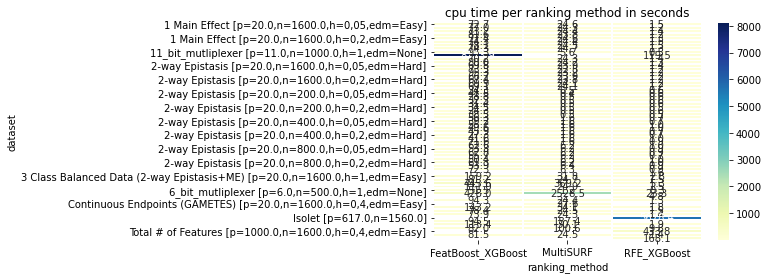

In [21]:
rectangular = pd.pivot_table(rankdata, values='cpu_time', index=['dataset'], columns=['ranking_method'])
g = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu")
plt.title('cpu time per ranking method in seconds')

In [4]:
# sns.catplot(x="dataset_no", y="cpu_time", hue="ranking_method", 
#             data=all_results, col="dataset", col_wrap=4, kind="bar", 
#             facet_kws={'sharey': False})

## Validation results
Validation using KNN.

In [ ]:
ft = valdata[valdata['ranking_method'] == 'RFE_XGBoost']
ft = ft[ft['dataset'].isin(datasets)]
g = sns.relplot(x="n_features", y="score",
            col="dataset", hue="dataset_no",
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=ft)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: int(x)))

ft2 = valdata[valdata['ranking_method'] == 'FeatBoost_XGBoost']
ft2 = ft2[ft2['dataset'].isin(datasets)]
g2 = sns.relplot(x="n_features", y="score",
            col="dataset", hue="dataset_no",
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=ft2)

In [ ]:
ft_both = valdata[valdata['dataset'].isin(datasets)]
g_both = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=ft_both)

All validation results in 1 plot.

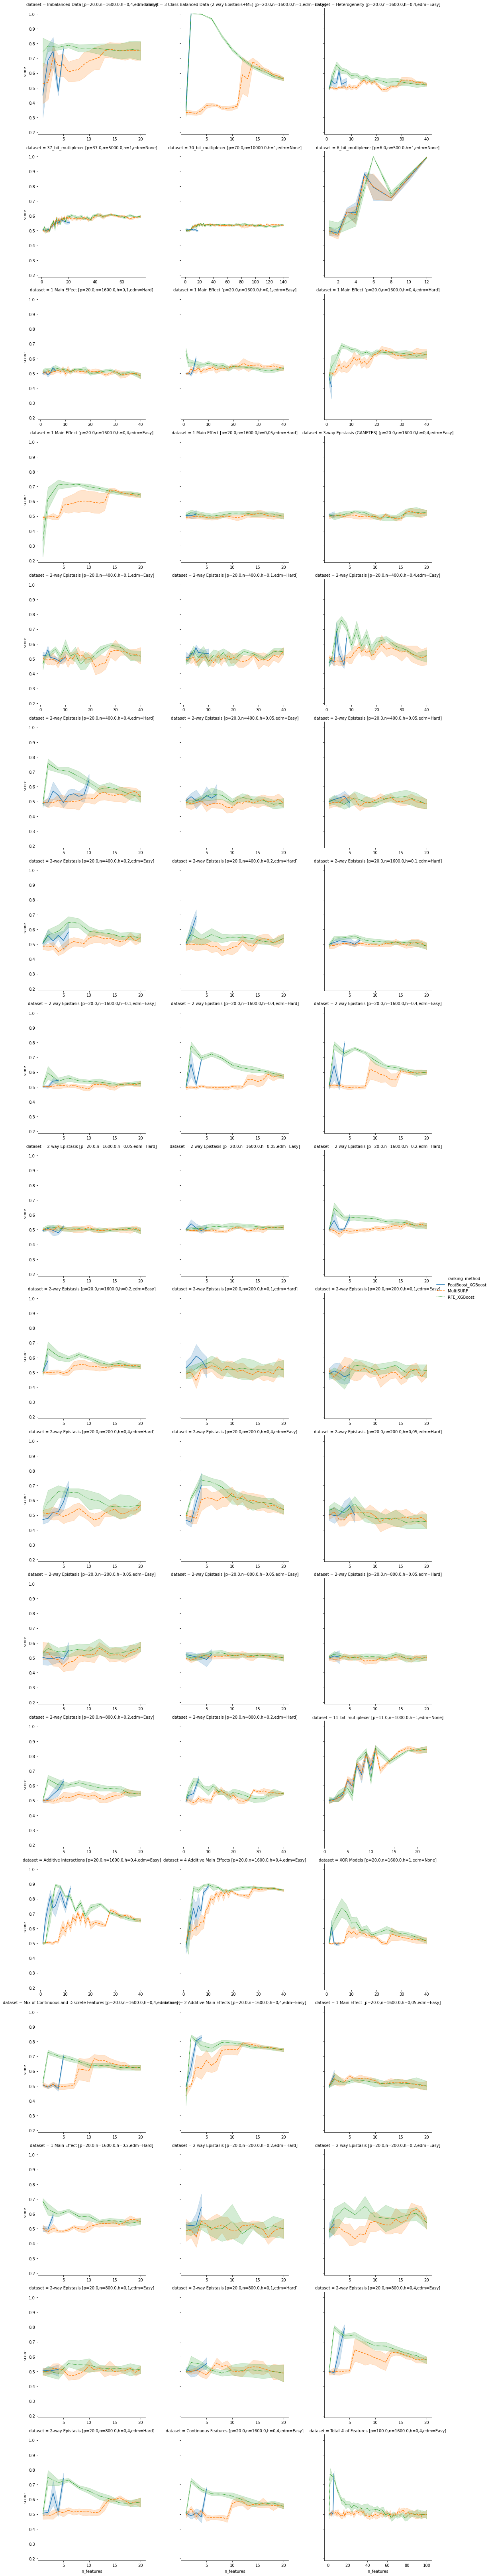

In [24]:
g = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            style="ranking_method", kind="line",
            col_wrap=3,
            facet_kws={'sharex': False},
            data=valdata)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: int(x)))
g.savefig('validation-results.png')

Selected subset of results

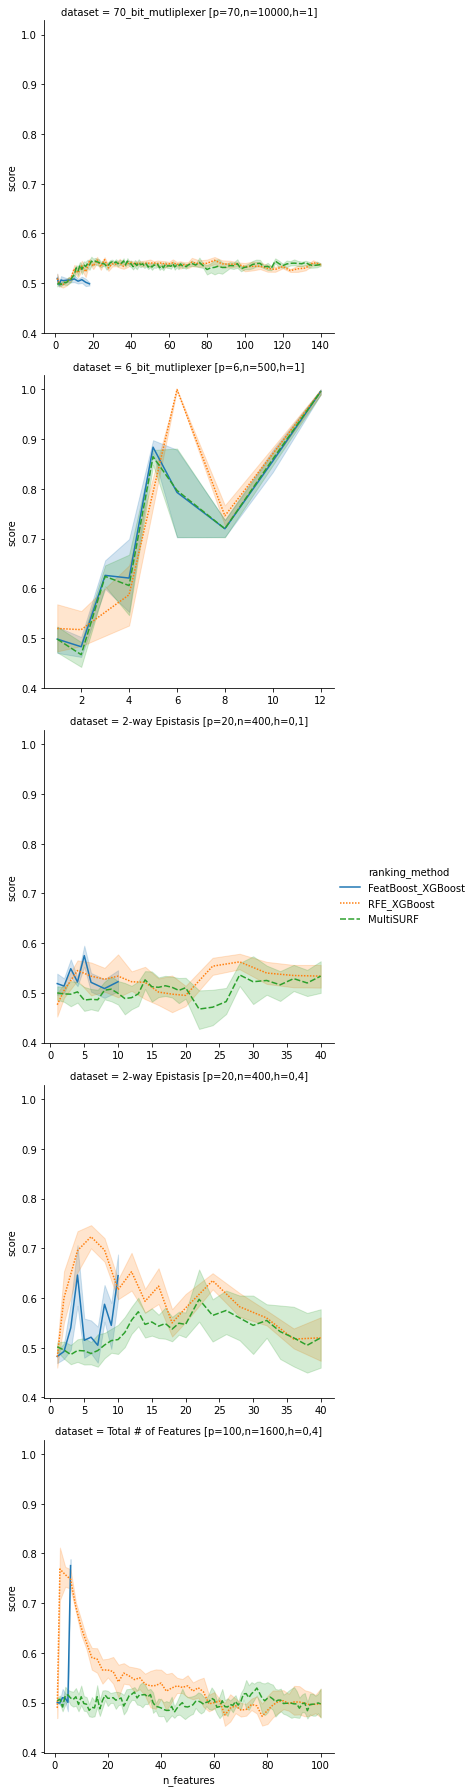

In [4]:
datasets = [
    '6_bit_mutliplexer [p=6,n=500,h=1]',
    '70_bit_mutliplexer [p=70,n=10000,h=1]',
    'Total # of Features [p=100,n=1600,h=0,4]',
    'Total # of Features [p=1000,n=1600,h=0,4]',
    '2-way Epistasis [p=20,n=400,h=0,1]',
    '2-way Epistasis [p=20,n=400,h=0,1]',
    '2-way Epistasis [p=20,n=400,h=0,4]',
]
ft_both = valdata[valdata['dataset'].isin(datasets)]
g_both = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            hue_order=["FeatBoost_XGBoost", "RFE_XGBoost", "MultiSURF"],
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=ft_both)